# 3. Heurísticas constructivas, búsqueda local y óptimos locales

El capítulo 1 mostró que enumerar todas las soluciones es imposible incluso en instancias moderadas y que el muestreo aleatorio desperdicia la información que recoge. Este capítulo presenta las dos herramientas sobre las que se construyen casi todas las metaheurísticas del libro. La primera son las heurísticas constructivas, que arman una solución paso a paso con una regla sencilla. La segunda es la búsqueda local, que mejora una solución completa con cambios pequeños hasta que ningún cambio la mejora. Las dos se aplican a la mochila, las $n$ reinas y el agente viajero, y la última sección muestra su límite, el óptimo local, que motiva el resto del libro.

In [1]:
import itertools
import math
import random
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

## Instancias

El capítulo usa las instancias del capítulo 1, que la celda siguiente vuelve a generar con la misma semilla. Los valores óptimos de la mochila de 20 objetos y del recorrido por las 10 primeras ciudades se obtuvieron allí por enumeración.

In [2]:
np.random.seed(42)
random.seed(42)

# Mochila: 20 objetos
N_OBJETOS = 20
pesos = np.random.randint(1, 31, size=N_OBJETOS)
valores = np.random.randint(1, 51, size=N_OBJETOS)
capacidad = int(0.4 * pesos.sum())
OPTIMO_MOCHILA = 402  # Por enumeración, capítulo 1

# Agente viajero: 50 ciudades; las 10 primeras forman la instancia pequeña
N_CIUDADES = 50
ciudades = np.random.uniform(0, 100, size=(N_CIUDADES, 2))
distancias = np.sqrt(((ciudades[:, None, :] - ciudades[None, :, :]) ** 2).sum(axis=2))
d10 = distancias[:10, :10]
OPTIMO_VIAJERO_10 = 223.07  # Por enumeración, capítulo 1


def valor_mochila(x, pesos, valores, capacidad):
    """Valor total de la selección x, o None si excede la capacidad."""
    if np.dot(x, pesos) > capacidad:
        return None
    return int(np.dot(x, valores))


def longitud_recorrido(ruta, distancias):
    """Longitud del ciclo que visita las ciudades en el orden de ruta."""
    return sum(distancias[ruta[k], ruta[(k + 1) % len(ruta)]] for k in range(len(ruta)))


def conflictos(s):
    """Pares de reinas que se atacan en diagonal, contando reinas por diagonal."""
    diag1 = Counter(i - fila for i, fila in enumerate(s))
    diag2 = Counter(i + fila for i, fila in enumerate(s))
    return sum(c * (c - 1) // 2 for c in diag1.values()) + sum(c * (c - 1) // 2 for c in diag2.values())

La función `conflictos` cuenta los mismos pares que la del capítulo 1, pero de otra forma. Dos reinas en las columnas $i$ y $j$ se atacan en diagonal si $i - s_i = j - s_j$ o si $i + s_i = j + s_j$, de modo que basta contar cuántas reinas hay en cada diagonal; una diagonal con $c$ reinas aporta $c(c-1)/2$ pares. Este cálculo recorre las reinas una sola vez, mientras que comparar todos los pares crece con $n^2$, y la diferencia pesa en la búsqueda local, que evalúa miles de soluciones.

## Heurísticas constructivas

Una heurística constructiva parte de una solución vacía y le agrega un elemento a la vez, escogiendo en cada paso el que parece mejor según una regla local, sin deshacer las decisiones anteriores. Las tres de la celda siguiente son las más conocidas para cada problema:

- la heurística voraz (*greedy*) de la mochila ordena los objetos de mayor a menor valor por unidad de peso, $v_i/w_i$, y los agrega en ese orden mientras quepan;
- el vecino más cercano (*nearest neighbor*) del agente viajero parte de una ciudad y va siempre a la ciudad no visitada más cercana, y al final vuelve a la de partida;
- la heurística de las reinas recorre las columnas de izquierda a derecha y ubica cada reina en la fila libre con menos ataques a las reinas ya ubicadas; si varias filas empatan, escoge una al azar.

In [3]:
def voraz_mochila(pesos, valores, capacidad):
    """Agrega los objetos en orden de valor por unidad de peso mientras quepan."""
    orden = np.argsort(-valores / pesos)
    x = np.zeros(len(pesos), dtype=int)
    peso = 0
    for i in orden:
        if peso + pesos[i] <= capacidad:
            x[i] = 1
            peso += pesos[i]
    return x


def vecino_mas_cercano(distancias, inicio=0):
    """Construye un recorrido yendo siempre a la ciudad no visitada más cercana."""
    n = len(distancias)
    ruta = [inicio]
    pendientes = set(range(n)) - {inicio}
    while pendientes:
        actual = ruta[-1]
        siguiente = min(pendientes, key=lambda j: distancias[actual, j])
        ruta.append(siguiente)
        pendientes.remove(siguiente)
    return ruta


def reinas_constructiva(n):
    """Ubica una reina por columna, en la fila libre con menos conflictos con las ya ubicadas."""
    s = []
    filas_libres = set(range(n))
    for col in range(n):
        def ataques(fila):
            return sum(1 for c, f in enumerate(s) if abs(f - fila) == col - c)
        menor = min(ataques(f) for f in filas_libres)
        candidatas = [f for f in filas_libres if ataques(f) == menor]
        fila = random.choice(candidatas)  # Desempate al azar
        s.append(fila)
        filas_libres.remove(fila)
    return s

In [4]:
random.seed(42)

x_voraz = voraz_mochila(pesos, valores, capacidad)
print(f"Mochila, voraz: valor {valor_mochila(x_voraz, pesos, valores, capacidad)} "
      f"(óptimo {OPTIMO_MOCHILA}), peso {np.dot(x_voraz, pesos)} de {capacidad}")

ruta_vmc10 = vecino_mas_cercano(d10)
print(f"Viajero, 10 ciudades, vecino más cercano: {longitud_recorrido(ruta_vmc10, d10):.2f} "
      f"(óptimo {OPTIMO_VIAJERO_10})")
longitudes_vmc50 = [longitud_recorrido(vecino_mas_cercano(distancias, i), distancias) for i in range(N_CIUDADES)]
print(f"Viajero, 50 ciudades, vecino más cercano desde la ciudad 0: {longitudes_vmc50[0]:.2f}; "
      f"desde las 50 ciudades: entre {min(longitudes_vmc50):.2f} y {max(longitudes_vmc50):.2f}")

for n in [8, 30]:
    resultados = [conflictos(reinas_constructiva(n)) for _ in range(100)]
    print(f"Reinas, n = {n}, constructiva en 100 corridas: conflictos entre {min(resultados)} y {max(resultados)}, "
          f"{sum(r == 0 for r in resultados)} sin conflictos")

Mochila, voraz: valor 396 (óptimo 402), peso 125 de 128
Viajero, 10 ciudades, vecino más cercano: 223.37 (óptimo 223.07)
Viajero, 50 ciudades, vecino más cercano desde la ciudad 0: 667.23; desde las 50 ciudades: entre 643.25 y 756.27
Reinas, n = 8, constructiva en 100 corridas: conflictos entre 0 y 4, 9 sin conflictos
Reinas, n = 30, constructiva en 100 corridas: conflictos entre 0 y 6, 4 sin conflictos


Las tres heurísticas dan soluciones buenas en muy poco tiempo, sin garantía de que sean óptimas. La voraz llena la mochila hasta 125 de las 128 unidades de capacidad y obtiene 396, a seis unidades del óptimo de 402. En las 10 primeras ciudades, el vecino más cercano construye un recorrido de 223,37, casi el óptimo de 223,07. En las 50 ciudades el resultado depende de la ciudad de partida y va de 643,25 a 756,27; desde la ciudad 0 es 667,23. La heurística de las reinas deja pocos conflictos, como máximo 4 en el tablero de $8 \times 8$ y 6 en el de $30 \times 30$, pero solo termina sin conflictos en 9 y en 4 de las 100 corridas, respectivamente. Como cada reina se ubica sin mirar las que faltan, las últimas columnas solo pueden escoger entre las pocas filas que quedan libres.

## Vecindarios

La búsqueda local necesita una noción de cercanía entre soluciones. El vecindario $N(x)$ de una solución $x$ es el conjunto de soluciones que se obtienen de $x$ con un cambio pequeño, llamado movimiento. Los vecindarios del capítulo son los siguientes:

- en la mochila, el movimiento *flip* cambia el estado de un objeto, que sale si estaba o entra si no estaba, y el intercambio saca un objeto y mete otro; solo se consideran los vecinos que caben en la mochila, y con $n$ objetos, de los cuales $k$ están dentro, hay $n$ movimientos *flip* y $k(n-k)$ intercambios;
- en las reinas, el movimiento intercambia las filas de dos columnas, lo que conserva la permutación, y hay $n(n-1)/2$ vecinos;
- en el agente viajero, el movimiento 2-opt quita dos arcos del recorrido y reconecta los dos tramos que quedan de la otra forma posible, lo que equivale a invertir el orden de las ciudades de uno de los tramos, y hay $n(n-3)/2$ vecinos; el intercambio de dos ciudades del recorrido es otro vecindario posible, con $n(n-1)/2$ vecinos.

El tamaño del vecindario fija el costo de revisarlo completo, y en los tres problemas crece con $n$.

In [5]:
def vecinos_flip(x, pesos, capacidad):
    """Soluciones factibles que difieren de x en un objeto (sale o entra)."""
    vecinos = []
    for i in range(len(x)):
        y = x.copy()
        y[i] = 1 - y[i]
        if np.dot(y, pesos) <= capacidad:
            vecinos.append(y)
    return vecinos


def vecinos_intercambio(x, pesos, capacidad):
    """Soluciones factibles que sacan un objeto de x y meten otro que no estaba."""
    vecinos = []
    dentro = np.flatnonzero(x == 1)
    fuera = np.flatnonzero(x == 0)
    for i in dentro:
        for j in fuera:
            y = x.copy()
            y[i], y[j] = 0, 1
            if np.dot(y, pesos) <= capacidad:
                vecinos.append(y)
    return vecinos


def vecinos_reinas(s):
    """Permutaciones que intercambian las filas de dos columnas."""
    vecinos = []
    n = len(s)
    for i in range(n - 1):
        for j in range(i + 1, n):
            t = list(s)
            t[i], t[j] = t[j], t[i]
            vecinos.append(t)
    return vecinos


n = 20
print(f"Tamaño de los vecindarios con n = {n}:")
print(f"  mochila, flip: {n}; intercambio: k(n - k), como máximo {n * n // 4}")
print(f"  reinas, intercambio de filas: n(n - 1)/2 = {n * (n - 1) // 2}")
print(f"  viajero, intercambio de dos ciudades: n(n - 1)/2 = {n * (n - 1) // 2}; 2-opt: n(n - 3)/2 = {n * (n - 3) // 2}")

Tamaño de los vecindarios con n = 20:
  mochila, flip: 20; intercambio: k(n - k), como máximo 100
  reinas, intercambio de filas: n(n - 1)/2 = 190
  viajero, intercambio de dos ciudades: n(n - 1)/2 = 190; 2-opt: n(n - 3)/2 = 170


## Búsqueda local

La búsqueda local, o ascenso de colinas (*hill climbing*), parte de una solución y se mueve repetidamente a un vecino mejor, hasta que ningún vecino mejora la solución actual. La función `ascenso_colinas` la implementa para cualquier problema. Recibe la solución inicial, una función que genera el vecindario y la función de costo que se minimiza; en la mochila, el costo es el valor con signo cambiado.

Hay dos maneras de escoger el vecino. En la primera mejora (*first improvement*) los vecinos se revisan en orden aleatorio y la búsqueda se mueve al primero que mejora la solución. En la mejor mejora (*best improvement*) se revisan todos y la búsqueda se mueve al mejor. La primera mejora da pasos más baratos y la mejor mejora da pasos más grandes.

La búsqueda termina en una solución $\hat{x}$ que ningún vecino mejora,

$$f(\hat{x}) \le f(y) \quad \text{para todo } y \in N(\hat{x}),$$

llamada óptimo local con respecto al vecindario $N$. Un óptimo global es óptimo local para cualquier vecindario, pero un óptimo local puede estar lejos del global.

In [6]:
def ascenso_colinas(x0, vecinos, costo, estrategia='mejor'):
    """
    Búsqueda local que minimiza costo. En cada paso revisa el vecindario de la
    solución actual y se mueve a un vecino mejor: el primero que encuentra
    (estrategia='primera', con los vecinos en orden aleatorio) o el mejor de todos
    (estrategia='mejor'). Se detiene cuando ningún vecino mejora la solución.
    Devuelve la solución final, su costo y el número de evaluaciones.
    """
    x, cx = x0, costo(x0)
    evaluaciones = 1
    while True:
        lista = vecinos(x)
        if estrategia == 'primera':
            random.shuffle(lista)
        mejor_vecino, mejor_costo = None, cx
        for y in lista:
            cy = costo(y)
            evaluaciones += 1
            if cy < mejor_costo:
                mejor_vecino, mejor_costo = y, cy
                if estrategia == 'primera':
                    break
        if mejor_vecino is None:
            return x, cx, evaluaciones
        x, cx = mejor_vecino, mejor_costo

Para el agente viajero, la función `dos_opt` no calcula desde cero la longitud de cada vecino. Si el movimiento quita los arcos $(a,b)$ y $(c,d)$ y pone $(a,c)$ y $(b,d)$, la longitud cambia en

$$\Delta = d_{ac} + d_{bd} - d_{ab} - d_{cd},$$

y el movimiento mejora el recorrido si $\Delta < 0$. Evaluar un vecino cuesta así cuatro consultas a la matriz de distancias, en lugar de las $n$ sumas de la longitud completa. Calcular solo el cambio que produce un movimiento es una técnica que se repite en muchas metaheurísticas.

In [7]:
def dos_opt(ruta, distancias, estrategia='mejor'):
    """
    Búsqueda local 2-opt para el agente viajero. Un movimiento quita los arcos
    (a, b) y (c, d) e invierte el tramo entre b y c; su efecto en la longitud se
    calcula con los cuatro arcos que cambian. Devuelve la ruta final, su longitud
    y el número de movimientos evaluados.
    """
    ruta = list(ruta)
    n = len(ruta)
    evaluaciones = 0
    mejora = True
    while mejora:
        mejora = False
        mejor_delta, mejor_mov = -1e-9, None
        pares = [(i, j) for i in range(n - 1) for j in range(i + 2, n) if not (i == 0 and j == n - 1)]
        if estrategia == 'primera':
            random.shuffle(pares)
        for i, j in pares:
            a, b = ruta[i], ruta[i + 1]
            c, d = ruta[j], ruta[(j + 1) % n]
            delta = distancias[a, c] + distancias[b, d] - distancias[a, b] - distancias[c, d]
            evaluaciones += 1
            if delta < mejor_delta:
                mejor_delta, mejor_mov = delta, (i, j)
                if estrategia == 'primera':
                    break
        if mejor_mov is not None:
            i, j = mejor_mov
            ruta[i + 1:j + 1] = ruta[i + 1:j + 1][::-1]
            mejora = True
    return ruta, longitud_recorrido(ruta, distancias), evaluaciones

### Primera mejora y mejor mejora

La celda siguiente compara las dos estrategias desde 30 soluciones iniciales aleatorias por problema. En la mochila, cada solución inicial toma los objetos en orden aleatorio y mete cada uno con probabilidad 1/2 si cabe; en las reinas y en el agente viajero es una permutación aleatoria. Para cada problema y estrategia, la tabla informa el promedio y el mejor de los 30 resultados finales (valor en la mochila, conflictos en el tablero de $30 \times 30$ y longitud en las 50 ciudades) y el número promedio de vecinos evaluados.

In [8]:
def costo_mochila(x):
    """Costo a minimizar: el valor con signo cambiado (los vecinos ya son factibles)."""
    return -int(np.dot(x, valores))


def vecinos_mochila(x):
    return vecinos_flip(x, pesos, capacidad) + vecinos_intercambio(x, pesos, capacidad)


def inicio_mochila():
    """Selección aleatoria factible: objetos en orden aleatorio mientras quepan."""
    x = np.zeros(N_OBJETOS, dtype=int)
    peso = 0
    for i in np.random.permutation(N_OBJETOS):
        if np.random.random() < 0.5 and peso + pesos[i] <= capacidad:
            x[i] = 1
            peso += pesos[i]
    return x


random.seed(42)
np.random.seed(42)
num_inicios = 30
filas = []
for estrategia in ['primera', 'mejor']:
    # Mochila, 20 objetos
    res = [ascenso_colinas(inicio_mochila(), vecinos_mochila, costo_mochila, estrategia) for _ in range(num_inicios)]
    filas.append(('Mochila', estrategia, np.mean([-r[1] for r in res]), max(-r[1] for r in res), np.mean([r[2] for r in res])))
    # Reinas, 30 x 30
    res = [ascenso_colinas(list(np.random.permutation(30)), vecinos_reinas, conflictos, estrategia) for _ in range(num_inicios)]
    filas.append(('Reinas 30', estrategia, np.mean([r[1] for r in res]), min(r[1] for r in res), np.mean([r[2] for r in res])))
    # Viajero, 50 ciudades
    res = [dos_opt(list(np.random.permutation(N_CIUDADES)), distancias, estrategia) for _ in range(num_inicios)]
    filas.append(('Viajero 50', estrategia, np.mean([r[1] for r in res]), min(r[1] for r in res), np.mean([r[2] for r in res])))

print(f"{'Problema':<11} | {'estrategia':<8} | {'promedio':>9} | {'mejor':>8} | {'evaluaciones promedio':>21}")
print("-" * 70)
for problema in ['Mochila', 'Reinas 30', 'Viajero 50']:
    for f in filas:
        if f[0] == problema:
            print(f"{f[0]:<11} | {f[1]:<8} | {f[2]:>9.2f} | {f[3]:>8.2f} | {f[4]:>21,.0f}")

Problema    | estrategia |  promedio |    mejor | evaluaciones promedio
----------------------------------------------------------------------
Mochila     | primera  |    392.00 |   402.00 |                   122
Mochila     | mejor    |    394.00 |   402.00 |                   491
Reinas 30   | primera  |      1.13 |     0.00 |                   839
Reinas 30   | mejor    |      1.07 |     0.00 |                 3,524
Viajero 50  | primera  |    603.20 |   569.32 |                 5,812
Viajero 50  | mejor    |    592.24 |   561.55 |                53,384


En los tres problemas, la primera mejora evalúa muchos menos vecinos, unas cuatro veces menos en la mochila y en las reinas y unas nueve veces menos en el agente viajero. La calidad final es parecida. La mejor mejora termina, en promedio, con un valor algo mayor en la mochila (394 frente a 392) y con recorridos algo más cortos en el viajero (592,24 frente a 603,20), y en las reinas las dos terminan con cerca de un conflicto en promedio. Con 30 inicios por estrategia, esas diferencias de calidad no permiten preferir una de las dos; las de costo sí son claras. Las dos estrategias llegan alguna vez al óptimo de la mochila y a un tablero sin conflictos, pero ninguna lo hace siempre, y la sección siguiente explica por qué.

## El problema de los óptimos locales

Que la búsqueda local se detenga no significa que haya encontrado la mejor solución, solo que ningún movimiento del vecindario la mejora. La figura siguiente lo muestra con una función de una variable con varios mínimos,

$$f(x) = 0{,}05\,x^2 - \cos(2x) - 0{,}5\,\sin(5x),$$

discretizada en una malla de paso 0,05 entre $-8$ y 8. Desde cada uno de 12 puntos de partida al azar, el ascenso de colinas se mueve al vecino de la malla de menor valor hasta que ninguno de los dos vecinos mejora. Cada tramo de color es una trayectoria y cada punto negro, su llegada.

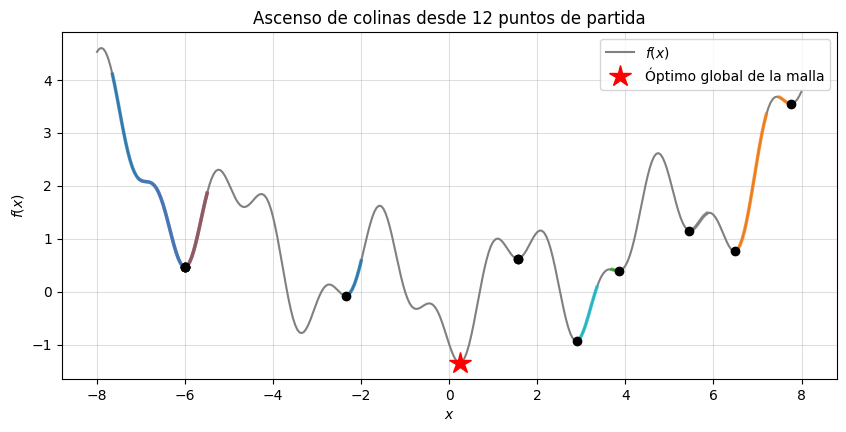

Puntos de llegada distintos: [-6.0, -2.35, 1.55, 2.9, 3.85, 5.45, 6.5, 7.75]
Óptimo global de la malla: x = 0.25, f(x) = -1.349


In [9]:
def f_multimodal(x):
    return 0.05 * x ** 2 - np.cos(2 * x) - 0.5 * np.sin(5 * x)


malla = np.round(np.arange(-8, 8.001, 0.05), 2)


def ascenso_malla(x0):
    """Ascenso de colinas sobre la malla: se mueve al vecino (±0,05) de menor valor."""
    k = int(np.argmin(np.abs(malla - x0)))
    trayectoria = [k]
    while True:
        candidatos = [j for j in (k - 1, k + 1) if 0 <= j < len(malla)]
        mejor = min(candidatos, key=lambda j: f_multimodal(malla[j]))
        if f_multimodal(malla[mejor]) >= f_multimodal(malla[k]):
            return trayectoria
        k = mejor
        trayectoria.append(k)


np.random.seed(42)
inicios = np.random.uniform(-8, 8, size=12)
plt.figure(figsize=(10, 4.5))
plt.plot(malla, f_multimodal(malla), color='gray', label='$f(x)$')
finales = []
for x0 in inicios:
    tray = ascenso_malla(x0)
    plt.plot(malla[tray], f_multimodal(malla[tray]), linewidth=2.5, alpha=0.8)
    plt.plot(malla[tray[-1]], f_multimodal(malla[tray[-1]]), 'ko', markersize=6)
    finales.append(round(float(malla[tray[-1]]), 2))
x_global = malla[np.argmin(f_multimodal(malla))]
plt.plot(x_global, f_multimodal(x_global), 'r*', markersize=16, label='Óptimo global de la malla')
plt.xlabel('$x$')
plt.ylabel('$f(x)$')
plt.title('Ascenso de colinas desde 12 puntos de partida')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()
print(f"Puntos de llegada distintos: {sorted(set(finales))}")
print(f"Óptimo global de la malla: x = {x_global:.2f}, f(x) = {f_multimodal(x_global):.3f}")

Las 12 trayectorias terminan en 8 puntos distintos, y ninguno es el óptimo global de la malla, en $x = 0{,}25$. Cada trayectoria baja hasta el fondo del valle en el que empezó y se detiene, porque para salir tendría que subir. El punto de llegada depende solo del punto de partida, y el óptimo global se alcanza únicamente si se parte dentro de su valle. En los problemas combinatorios pasa lo mismo, aunque no se pueda dibujar. Allí el vecindario define qué soluciones son vecinas y, con ello, la forma de los valles.

### La mochila

La instancia pequeña de la celda siguiente muestra cómo falla la heurística voraz y por qué la búsqueda local no la corrige. Hay cuatro objetos, con pesos 6, 5, 5 y 1 y valores 30, 20, 20 y 1, y la capacidad es 10. El objeto 0 tiene la mayor razón de valor por peso, 5, y la voraz lo mete primero; después no cabe ni el objeto 1 ni el 2, y solo entra el objeto 3.

In [10]:
pesos_p = np.array([6, 5, 5, 1])
valores_p = np.array([30, 20, 20, 1])
capacidad_p = 10

x_voraz_p = voraz_mochila(pesos_p, valores_p, capacidad_p)
print(f"Voraz: objetos {np.flatnonzero(x_voraz_p).tolist()}, valor {valor_mochila(x_voraz_p, pesos_p, valores_p, capacidad_p)}")

x_local_p, c_local_p, _ = ascenso_colinas(
    x_voraz_p,
    lambda x: vecinos_flip(x, pesos_p, capacidad_p) + vecinos_intercambio(x, pesos_p, capacidad_p),
    lambda x: -int(np.dot(x, valores_p)))
print(f"Búsqueda local desde la voraz: objetos {np.flatnonzero(x_local_p).tolist()}, valor {-c_local_p}")

for vecino in vecinos_flip(x_voraz_p, pesos_p, capacidad_p) + vecinos_intercambio(x_voraz_p, pesos_p, capacidad_p):
    print(f"  vecino factible {np.flatnonzero(vecino).tolist()}: valor {int(np.dot(vecino, valores_p))}")

optimo_p = max((valor_mochila(np.array(x), pesos_p, valores_p, capacidad_p) or 0, x)
               for x in itertools.product((0, 1), repeat=4))
print(f"Óptimo por enumeración: objetos {np.flatnonzero(optimo_p[1]).tolist()}, valor {optimo_p[0]}")

Voraz: objetos [0, 3], valor 31
Búsqueda local desde la voraz: objetos [0, 3], valor 31
  vecino factible [3]: valor 1
  vecino factible [0]: valor 30
  vecino factible [1, 3]: valor 21
  vecino factible [2, 3]: valor 21
Óptimo por enumeración: objetos [1, 2], valor 40


La voraz obtiene 31, y el óptimo, que lleva los objetos 1 y 2, vale 40. La búsqueda local con los vecindarios *flip* e intercambio no sale de la solución voraz, porque sus cuatro vecinos factibles valen 1, 30, 21 y 21. Para llegar al óptimo hay que sacar el objeto 0 y meter los objetos 1 y 2 a la vez, un cambio de tres objetos que ningún movimiento de los dos vecindarios hace. La solución voraz es un óptimo local, y el global está a más de un movimiento de distancia.

In [11]:
random.seed(42)
np.random.seed(42)
x_local_voraz, c, _ = ascenso_colinas(x_voraz, vecinos_mochila, costo_mochila, 'mejor')
print(f"Búsqueda local desde la solución voraz: valor {-c} (voraz {valor_mochila(x_voraz, pesos, valores, capacidad)}, "
      f"óptimo {OPTIMO_MOCHILA})")

finales_mochila = [-ascenso_colinas(inicio_mochila(), vecinos_mochila, costo_mochila, 'mejor')[1] for _ in range(100)]
conteo = Counter(finales_mochila)
print(f"Búsqueda local desde 100 selecciones aleatorias: {len(conteo)} valores finales distintos; "
      f"{conteo[OPTIMO_MOCHILA]} llegan al óptimo")
print(f"Valores finales más frecuentes: {conteo.most_common(6)}")

Búsqueda local desde la solución voraz: valor 398 (voraz 396, óptimo 402)
Búsqueda local desde 100 selecciones aleatorias: 3 valores finales distintos; 47 llegan al óptimo
Valores finales más frecuentes: [(382, 52), (402, 47), (398, 1)]


En la instancia de 20 objetos, la búsqueda local mejora la solución voraz de 396 a 398, pero no llega al óptimo de 402. Desde 100 selecciones aleatorias, la búsqueda termina en solo tres valores distintos: 47 corridas llegan al óptimo, 52 se detienen en 382 y una en 398. Como en la función de una variable, el resultado depende del punto de partida, y en esta instancia algo más de la mitad de los puntos de partida lleva a un óptimo local que no es el global.

### El agente viajero

La celda siguiente aplica 2-opt con mejor mejora desde 100 recorridos aleatorios, primero en la instancia de 10 ciudades y luego en la de 50, y también desde el recorrido del vecino más cercano que parte de la ciudad 0.

10 ciudades: 100 de 100 inicios llegan al óptimo; 1 longitudes finales distintas


50 ciudades: longitudes finales entre 556.84 y 650.97, 100 distintas en 100 inicios (2.2 s)
Vecino más cercano desde la ciudad 0 seguido de 2-opt: 587.88 (antes 667.23)


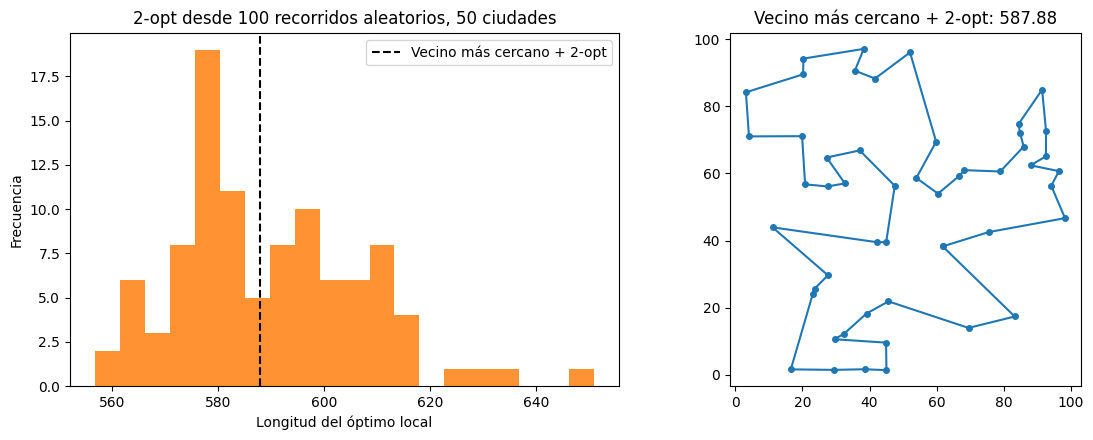

In [12]:
random.seed(42)
np.random.seed(42)

finales_10 = [dos_opt(list(np.random.permutation(10)), d10, 'mejor')[1] for _ in range(100)]
print(f"10 ciudades: {sum(abs(L - OPTIMO_VIAJERO_10) < 0.01 for L in finales_10)} de 100 inicios llegan al óptimo; "
      f"{len(set(np.round(finales_10, 2)))} longitudes finales distintas")

inicio = time.perf_counter()
finales_50 = [dos_opt(list(np.random.permutation(N_CIUDADES)), distancias, 'mejor')[1] for _ in range(100)]
print(f"50 ciudades: longitudes finales entre {min(finales_50):.2f} y {max(finales_50):.2f}, "
      f"{len(set(np.round(finales_50, 2)))} distintas en 100 inicios ({time.perf_counter() - inicio:.1f} s)")

ruta_vmc_2opt, L_vmc_2opt, _ = dos_opt(vecino_mas_cercano(distancias, 0), distancias, 'mejor')
print(f"Vecino más cercano desde la ciudad 0 seguido de 2-opt: {L_vmc_2opt:.2f} (antes {longitudes_vmc50[0]:.2f})")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
ejes[0].hist(finales_50, bins=20, color='tab:orange', alpha=0.85)
ejes[0].axvline(L_vmc_2opt, color='black', linestyle='--', label='Vecino más cercano + 2-opt')
ejes[0].set_xlabel('Longitud del óptimo local')
ejes[0].set_ylabel('Frecuencia')
ejes[0].set_title('2-opt desde 100 recorridos aleatorios, 50 ciudades')
ejes[0].legend()

for eje_ruta, ruta, titulo in [(ejes[1], ruta_vmc_2opt, 'Vecino más cercano + 2-opt')]:
    puntos = ciudades[ruta + [ruta[0]]]
    eje_ruta.plot(puntos[:, 0], puntos[:, 1], 'o-', markersize=4)
    eje_ruta.set_title(f'{titulo}: {longitud_recorrido(ruta, distancias):.2f}')
    eje_ruta.set_aspect('equal')
plt.tight_layout()
plt.show()

En la instancia de 10 ciudades, los 100 inicios llegan al óptimo, de modo que con ese tamaño 2-opt no queda atrapado en óptimos locales, al menos desde estos puntos de partida. En la de 50 ciudades, en cambio, los 100 inicios terminan en 100 recorridos distintos, con longitudes entre 556,84 y 650,97. Cada uno es un óptimo local para 2-opt, y el peor es cerca de un 17 % más largo que el mejor. 2-opt mejora el recorrido del vecino más cercano de 667,23 a 587,88, un valor que queda en la mitad de la distribución, de modo que una buena solución inicial tampoco garantiza un buen óptimo local. El recorrido de la derecha no tiene cruces, porque en el plano un cruce siempre se puede deshacer con un movimiento 2-opt que acorta la ruta, pero no es el mejor que se encontró.

### Las $n$ reinas

En las reinas, la celda siguiente aplica la búsqueda local con mejor mejora desde 100 permutaciones aleatorias en los tableros de $8 \times 8$ y de $30 \times 30$, y luego examina el vecindario de una corrida que se detiene con conflictos.

In [13]:
random.seed(42)
np.random.seed(42)
for n in [8, 30]:
    finales = [ascenso_colinas(list(np.random.permutation(n)), vecinos_reinas, conflictos, 'mejor')[1] for _ in range(100)]
    conteo = Counter(finales)
    print(f"n = {n}: {conteo[0]} de 100 inicios terminan sin conflictos; conflictos finales {sorted(conteo.items())}")

# Una corrida que se detiene con conflictos: ¿cómo es su vecindario?
random.seed(1)
np.random.seed(1)
while True:
    s_final, c_final, _ = ascenso_colinas(list(np.random.permutation(30)), vecinos_reinas, conflictos, 'mejor')
    if c_final > 0:
        break
costos_vecinos = Counter(conflictos(t) for t in vecinos_reinas(s_final))
print(f"\nÓptimo local con {c_final} conflictos. Vecinos según su número de conflictos:")
print(f"  mejores: {sum(v for k, v in costos_vecinos.items() if k < c_final)}, "
      f"iguales: {costos_vecinos[c_final]}, peores: {sum(v for k, v in costos_vecinos.items() if k > c_final)}")

n = 8: 41 de 100 inicios terminan sin conflictos; conflictos finales [(0, 41), (1, 49), (2, 10)]


n = 30: 27 de 100 inicios terminan sin conflictos; conflictos finales [(0, 27), (1, 52), (2, 18), (3, 3)]

Óptimo local con 1 conflictos. Vecinos según su número de conflictos:
  mejores: 0, iguales: 11, peores: 424


La búsqueda local deja pocos conflictos, a lo sumo 2 en el tablero de $8 \times 8$ y 3 en el de $30 \times 30$, pero solo termina sin conflictos en 41 y en 27 de los 100 inicios. Los óptimos locales de las reinas tienen una forma particular. En la corrida examinada, la búsqueda se detiene con un conflicto; ninguno de sus 435 vecinos tiene menos conflictos, 11 tienen exactamente uno y los otros 424 tienen más. Esos 11 vecinos y la solución actual forman parte de una meseta (*plateau*), un conjunto de soluciones con el mismo costo que se conectan por movimientos. La búsqueda local solo acepta mejoras estrictas y no recorre la meseta, aunque desde alguno de sus puntos podría haber un movimiento que baje a cero conflictos. Las mesetas son frecuentes cuando la función objetivo toma pocos valores distintos, como el número de conflictos, y una estrategia que acepte movimientos laterales o peores las puede cruzar. El capítulo 4 presenta las primeras estrategias de ese tipo.